In [1]:
!pip install requests unpywall

  Preparing metadata (setup.py) ... done
  Created wheel for unpywall: filename=unpywall-0.2.3-py3-none-any.whl size=12251 sha256=f837719fc91adc21afe0d78e396bb26ea7ad9217406862542690b06d0be3b890
  Stored in directory: /root/.cache/pip/wheels/77/79/b7/ad61104f9086183c12c581f6acb115572fa50ee28a0fb9dd9e
Successfully built unpywall


In [2]:
!python -m pip install dask distributed

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 1.2 MB/s eta 0:00:00


In [3]:
import re
import requests
import os
import time
import pandas as pd
import json

In [4]:
def get_dataset_keys_from_lit(lit_data: dict) -> str:

    keys = set()
    doi = ""

    # 1. Check tags for gbifDOI
    tags = lit_data.get('tags', [])
    for tag in tags:
        if tag.startswith('gbifDOI:'):
            doi = tag.replace('gbifDOI:', '')
            # We need the UUID for the download link.
            # You can call the API to resolve DOI -> UUID
            ds_uuid = resolve_doi_to_uuid(doi)
            if ds_uuid: keys.add(ds_uuid)

    # 2. Check the (often missing) direct field
    if 'gbifDatasetKey' in lit_data:
        keys.update(lit_data['gbifDatasetKey'])

    # 3. Fallback: Regex search in abstract/websites for 10.15468 DOIs
    content = str(lit_data.get('abstract', '')) + str(lit_data.get('websites', ''))
    found_dois = re.findall(r'10\.15468/[a-z0-9]+', content)
    for doi in found_dois:
        ds_uuid = resolve_doi_to_uuid(doi)
        if ds_uuid: keys.add(ds_uuid)

    return json.dumps({"doi": doi, "keys": list(keys)})

def resolve_doi_to_uuid(doi: str) -> str:
    """Queries GBIF to turn a DOI into a Dataset UUID"""
    res = requests.get(f"https://api.gbif.org/v1/dataset/doi/{doi}")
    if res.status_code == 200:
        return res.json().get('key')
    return None

In [5]:
def get_literature_metadata(id: str) -> str:
    api_url = f"https://api.gbif.org/v1/literature/{id}"
    response = requests.get(api_url)
    return response.text

In [6]:
def get_dataset_metadata(id_data: dict) -> str:
  if "doi" in id_data:
      response = requests.get(f"https://api.gbif.org/v1/dataset/doi/{id_data["doi"]}")
      if response.ok:
         return response.text
  return json.dumps({})

In [7]:
def get_dwca_download_url(dataset_data: dict) -> str:
  try:
      core_info = dataset_data["results"][0]
      dwca_endpoint = next((e for e in core_info["endpoints"] if e["type"] == "DWC_ARCHIVE"))
      return dwca_endpoint["url"]
  except:
      ...
  return ""

## Dataset Linking

In [8]:
df = pd.read_csv("/content/literature_1777369020244.tsv", sep="\t")

In [9]:
df

,title,authors,source,published,open_access,peer_review,citation_type,countries_of_coverage,countries_of_researcher,keywords,literature_type,websites,identifiers,id,abstract,topics,added,gbif_download_key
0,Coastal grassland vegetation records from São ...,Hugo Renato M.G. Calado|António O. Soares|Rube...,Biodiversity Data Journal,2025-11-24,True,True,DOI,PORTUGAL,PORTUGAL,Azores|coastal grasslands|mainland Portugal|oc...,JOURNAL,https://doi.org/10.3897/bdj.13.e173529,10.3897/bdj.13.e173529,6f97bcef-7324-3425-bb72-0dc035031776,BackgroundThe present work provides an invento...,DATA_PAPER,2026-04-24T12:22:44.256Z,NaN
1,Georeferenced checklist and occurrence dataset...,Tomasz Pawłowicz,Biodiversity Data Journal,2025-11-25,True,True,DOI,RUSSIAN_FEDERATION|CZECH_REPUBLIC|BELARUS|LATV...,POLAND,Central Europe|Eastern Europe|environmental co...,JOURNAL,https://doi.org/10.3897/bdj.13.e175486,10.3897/bdj.13.e175486,2fee34a0-a302-3c12-8916-bd915a1c0e50,"BackgroundA continental-scale, georeferenced c...",DATA_PAPER,2026-04-23T14:37:51.413Z,NaN
2,Dataset on bryophyte species distribution acro...,Rosalina Gabriel|Leila N. Morgado|Silvia Popon...,Biodiversity Data Journal,2025-11-19,True,True,DOI,PORTUGAL,PORTUGAL|ITALY,Azores|Flores Island|GIMS protocol|MOVECLIM-AZ...,JOURNAL,https://doi.org/10.3897/bdj.13.e165664,10.3897/bdj.13.e165664,325b19cf-6c16-3147-b8db-53b7acd7618f,BackgroundA bryophyte diversity survey was car...,DATA_PAPER,2026-04-21T11:38:36.940Z,NaN
3,Insights from the Dalberto Teixeira Pombo (DTP...,Luís Carlos Fonseca Crespo|Isabel R. Amorim|Fe...,Biodiversity Data Journal,2025-11-19,True,True,DOI,PORTUGAL,PORTUGAL,NaN,JOURNAL,https://doi.org/10.3897/bdj.13.e167838,10.3897/bdj.13.e167838,d72b6b4f-0fb1-301e-81d0-a8f62690b968,BackgroundThe second manuscript in the series ...,DATA_PAPER,2026-04-21T11:26:34.538Z,NaN
4,Sample event data on ground beetles (Coleopter...,Gijs M. Gerrits|Rikjan Vermeulen|Roel van Klink,Biodiversity Data Journal,2025-11-20,True,True,DOI,NETHERLANDS,NETHERLANDS|GERMANY,Dwingelderveld|Mantingerbos|Stichting Willem B...,JOURNAL,https://doi.org/10.3897/bdj.13.e171473,10.3897/bdj.13.e171473,93ed8a30-2f05-37c7-a371-1a18f739fc30,BackgroundHistorical data on invertebrates are...,DATA_PAPER,2026-04-20T14:23:02.473Z,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
333,Ground beetles (Carabidae) in urban habitats o...,Victor Aleksanov|Sergey Alekseev|Maxim Shashkov,Biodiversity Data Journal,2022-01-19,True,True,DOI,RUSSIAN_FEDERATION,RUSSIAN_FEDERATION,Central Russia|broadleaved forests|gardens|gra...,JOURNAL,https://doi.org/10.3897/bdj.10.e76100,10.3897/bdj.10.e76100,c4f96290-453c-3d85-8f54-fbee8114c354,"Ground beetles (Carabidae, Coleoptera) are one...",DATA_PAPER|ECOLOGY,2022-02-02T09:53:43.970Z,NaN
334,Small mammals of background areas in the vicin...,Svetlana Mukhacheva|Yulia Davydova|Artëm Sozontov,Biodiversity Data Journal,2022-01-13,True,True,generic,RUSSIAN_FEDERATION,RUSSIAN_FEDERATION,biological diversity|data paper|environmental ...,JOURNAL,https://doi.org/10.3897/bdj.10.e76215,10.3897/bdj.10.e76215,685915ac-55a0-3559-b491-507d79927b6a,The dataset contains records of small mammals ...,DATA_PAPER|ECOLOGY,2022-02-01T07:02:21.379Z,NaN
335,New records for crown wasps in Europe (Hymenop...,F. Ceccolini,Arxius de Miscel·lània Zoològica,2022-01-05,True,True,DOI,NaN,ITALY,Faunistics|Megischus anomalipes|New records|St...,JOURNAL,https://doi.org/10.32800/amz.2021.19.0249,10.32800/amz.2021.19.0249,8ecca78c-352e-3b83-a262-cc51ea722b96,New occurrence records for two species of Hyme...,DATA_PAPER,2022-01-27T14:39:47.044Z,NaN
336,Plant occurrences on the Rybachy and the Sredn...,Ksenia Popova|Anna Razumovskaya,Biodiversity Data Journal,2022-01-06,True,True,DOI,RUSSIAN_FEDERATION,RUSSIAN_FEDERATION,Barents Sea|Murmansk Region|Subarctic|databasi...,JOURNAL,https://doi.org/10.3897/bdj.10.e77094,10.3897/bdj.10.e77094,74a27d9e-8cac-36c2-a743-d9c7730b056d,The Rybachy and the Sredny Peninsul

### Collect GBIF Resource Metadata

> Using Dask Futures

In [10]:
from dask.distributed import Client, progress

In [11]:
d_client = Client(processes=False)

INFO:distributed.http.proxy:To route to workers diagnostics web server please install jupyter-server-proxy: python -m pip install jupyter-server-proxy
INFO:distributed.scheduler:State start
INFO:distributed.scheduler:  Scheduler at: inproc://172.28.0.12/53516/1
INFO:distributed.scheduler:  dashboard at:  http://172.28.0.12:8787/status
INFO:distributed.scheduler:Registering Worker plugin shuffle
INFO:distributed.worker:      Start worker at: inproc://172.28.0.12/53516/4
INFO:distributed.worker:         Listening to:          inproc172.28.0.12
INFO:distributed.worker:          Worker name:                          0
INFO:distributed.worker:         dashboard at:          172.28.0.12:39263
INFO:distributed.worker:Waiting to connect to: inproc://172.28.0.12/53516/1
INFO:distributed.worker:-------------------------------------------------
INFO:distributed.worker:              Threads:                          2
INFO:distributed.worker:               Memory:                  12.67 GiB
INFO:d

In [12]:
EXTENDED_LITERATURE_METADATA_CSV = "extended_literature_metadata.csv"

def extend_literature_info(df: pd.DataFrame) -> pd.DataFrame:
    # get the literature resource metadata
    futures = d_client.map(get_literature_metadata, df["id"].tolist())
    output = d_client.gather(futures)
    df["literature_metadata"] = output

    # get the dataset resource identifiers
    futures = d_client.map(
        lambda x: get_dataset_keys_from_lit(json.loads(x)),
        df["literature_metadata"].tolist()
    )
    output = d_client.gather(futures)
    df["gbif_data_id_data"] = output

    # get the dataset resource metadata
    futures = d_client.map(
        lambda r: get_dataset_metadata(json.loads(r)),
        df["gbif_data_id_data"].tolist()
    )
    output = d_client.gather(futures)
    df["dataset_metadata"] = output

    # get the dataset download URL
    futures = d_client.map(
        lambda r: get_dwca_download_url(json.loads(r)),
        df["dataset_metadata"].tolist()
    )
    output = d_client.gather(futures)
    df["dwca_url"] = output

    return df

In [13]:
try:
  elm_df = pd.read_csv(EXTENDED_LITERATURE_METADATA_CSV)
except:
  elm_df = extend_literature_info(df.copy())
  elm_df.to_csv(EXTENDED_LITERATURE_METADATA_CSV)

In [14]:
elm_df["dwca_url"].describe(include="all")

,dwca_url
count,324
unique,322
top,https://ipt.biodiversidad.co/sib/archive.do?r=...
freq,2


In [15]:
elm_df["dwca_url"].unique()

array(['https://ipt.gbif.pt/ipt/archive.do?r=coastal_plants',
       'https://ipt.pensoft.net/archive.do?r=eumycetozoa_central_eastern_europe',
       'http://ipt.gbif.pt/ipt/archive.do?r=moveclim_azores_flores_island_2012',
       'http://ipt.gbif.pt/ipt/archive.do?r=cave_trechus_algar',
       'https://ipt.nlbif.nl/archive.do?r=bsw_standard_series',
       'https://ipt.gbif.no/archive.do?r=tf-fl-norge',
       'https://ipt.gbif.fr/archive.do?r=cirad_astre_culicoides',
       'http://ipt.gbif.pt/ipt/archive.do?r=moniceph',
       'https://data.canadensys.net/micropublications/archive.do?r=specimen_53',
       'https://ipt.pensoft.net/archive.do?r=herpetofauna_las_piedras_peru',
       'https://ipt.sprep.org/archive.do?r=usp_apnford_to',
       'https://cloud.gbif.org/africa/archive.do?r=anopheles_mosquito',
       'https://cloud.gbif.org/africa/archive.do?r=anopheles_ghana_ecozones',
       'https://cloud.gbif.org/africa/archive.do?r=anopheles_phenotypic',
       'https://cloud.gbif.o

## Postprocessing

In [16]:
import numpy as np

In [17]:
CLEANED_EXTENDED_LITERATURE_METADATA_CSV = f"cleaned_{EXTENDED_LITERATURE_METADATA_CSV}"

def clean_incomplete_literature_info(df):
    df["dwca_url"] = df["dwca_url"].replace('', np.nan)
    cdf = df.copy()
    cdf = cdf.dropna(subset=["dwca_url"])
    cdf = cdf.dropna(subset=["identifiers"])
    return cdf

In [18]:
try:
    c_elm_df = pd.read_csv(CLEANED_EXTENDED_LITERATURE_METADATA_CSV)
except:
    c_elm_df = clean_incomplete_literature_info(elm_df)
    c_elm_df.to_csv(CLEANED_EXTENDED_LITERATURE_METADATA_CSV)

In [19]:
c_elm_df.describe(include="all")

,Unnamed: 0.1,Unnamed: 0,title,authors,source,published,open_access,peer_review,citation_type,countries_of_coverage,...,identifiers,id,abstract,topics,added,gbif_download_key,literature_metadata,gbif_data_id_data,dataset_metadata,dwca_url
count,316.000000,316.000000,316,316,316,316,316,316,316,299,...,316,316,314,316,316,6,316,316,316,316
unique,NaN,NaN,315,308,26,261,1,1,2,83,...,315,316,312,21,316,6,316,314,314,314
top,NaN,NaN,Occurrence dataset from the waterbird survey o...,Janakiraman Poorani,Biodiversity Data Journal,2025-05-22,True,True,DOI,RUSSIAN_FEDERATION,...,10.3897/bdj.13.e158384,08e3e1d4-f5e4-3ac0-9f19-f50b8249c05c,(no abstract available),DATA_PAPER,2022-01-27T12:21:30.292Z,0265120-230224095556074|0021321-230224095556074,"{""authors"":[{""firstName"":""Natalia"",""lastName"":...","{""doi"": ""10.15468/zeuqyd"", ""keys"": []}","{""offset"":0,""limit"":20,""endOfRecords"":true,""co...",http://www.gbifchina.org.cn/archive.do?r=occur...
freq,NaN,NaN,2,4,166,3,316,316,296,41,...,2,1,3,229,1,1,1,2,2,2
mean,169.968354,169.968354,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,97.933662,97.933662,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,86.750000,86.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,169.500000,169.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,252.250000,252.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
removed_titles = set(df["title"].tolist()) - set(c_elm_df["title"].tolist())

In [21]:
import pprint

In [22]:
pprint.pprint(removed_titles)
print(f"{len(removed_titles)}")

{'A combined microbial and biogeochemical dataset from high-latitude '
 'ecosystems with respect to methane cycle',
 'A long-term ecological research dataset from the marine genetic monitoring '
 'programme ARMS-MBON 2020-2021',
 'Bumble bees (Apidae: Bombus) and hover flies (Syrphidae) from the summits of '
 'the Gaspésie National Park, Québec',
 'Cinara stigmatica Hébert, Sano, and Favret 2023 from Japan (Insecta: '
 'Hemiptera: Aphididae)',
 'Citizen science helps in the study of fungal diversity in New Jersey',
 'Digitizing the Culicidae collection of Naturalis Biodiversity Center, with a '
 'special focus on the former Bonne-Wepster subcollection',
 'Finnish inventory data of underwater marine biodiversity',
 'Four species of Arctic mosquitoes (Insecta: Diptera: Culicidae: Aedes)',
 'Georeferencing herbarium specimens of the Naturalis botanical collection '
 'using automation and crowdsourcing',
 'Hover flies (Diptera: Syrphidae) from sweet alyssum flower strips in Quebec '
 'lett

In [23]:
dropped = elm_df[elm_df["title"].apply(lambda t: t in removed_titles)]

In [24]:
dropped.describe()

,Unnamed: 0
count,22.000000
mean,147.409091
std,94.165841
min,29.000000
25%,58.750000
50%,117.000000
75%,244.250000
max,294.000000


In [25]:
dropped.to_csv("dropped_extended_literature_metadata.csv")

## Downloads

In [98]:
import os
import shutil

In [27]:
os.makedirs("data", exist_ok=True)
os.makedirs("papers", exist_ok=True)

In [28]:
def make_data_file(idx: int, id: str) -> str:
    return f'data/{idx:03d}-{id}-download-data.zip'

def make_paper_file(idx: int, id: str) -> str:
    return f'papers/{idx:03d}-{id}-download-paper.pdf'

print(
    make_data_file(0, "fooo"),
    make_paper_file(10, "bar"),
)

data/000-fooo-download-data.zip papers/010-bar-download-paper.pdf


### Papers

In [99]:
def download_file(url, save_path) -> str:
    try:
        print(f"Saving `{url=}`->`{save_path=}`")
        with requests.get(url, stream=True, allow_redirects=True) as r:
            with open(save_path, 'wb') as f:
                shutil.copyfileobj(r.content, f)
        print(f"Saved `{save_path=}`")
        return save_path
    except Exception as e:
        print(e)
        return ""

In [100]:
from google.colab import userdata
UNPAYWALL_EMAIL = userdata.get('UNPAYWALL_EMAIL')

In [101]:
from unpywall.utils import UnpywallCredentials

UnpywallCredentials(UNPAYWALL_EMAIL)

Your email has been set.

In [102]:
from unpywall import Unpywall



> **WE FURHTER IGNORE ALL DOWNLOADS WHERE DOIs CAN NOT BE RESOLVED**



In [103]:
OPEN_ACCESS_EXTENDED_LITERATURE_METADATA_CSV = f"open-access_{EXTENDED_LITERATURE_METADATA_CSV}"

def resolve_open_access_endpoints(df):
    upw_df = Unpywall.doi(dois=df["identifiers"].tolist(), errors='ignore')
    upw_df = upw_df.dropna(subset="best_oa_location.url_for_pdf")
    upw_df = upw_df.set_index("doi")
    fdf = c_elm_df.join(upw_df, on="identifiers", how="inner", rsuffix="_unp")
    return fdf.drop_duplicates("identifiers")

In [104]:
try:
    fdf = pd.read_csv(OPEN_ACCESS_EXTENDED_LITERATURE_METADATA_CSV)
except:
    fdf = resolve_open_access_endpoints(c_elm_df)
    fdf.to_csv(OPEN_ACCESS_EXTENDED_LITERATURE_METADATA_CSV)

In [105]:
fdf.describe(include="all")

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,title,authors,source,published,open_access,peer_review,citation_type,...,first_oa_location.oa_date,first_oa_location.pmh_id,first_oa_location.repository_institution,first_oa_location.updated,first_oa_location.url,first_oa_location.url_for_landing_page,first_oa_location.url_for_pdf,first_oa_location.version,best_oa_location,first_oa_location
count,213.000000,213.000000,213.000000,213,213,213,213,213,213,213,...,213,1,0.0,213,213,213,213,213,0.0,0.0
unique,NaN,NaN,NaN,213,210,21,187,1,1,2,...,176,1,NaN,1,213,213,213,2,NaN,NaN
top,NaN,NaN,NaN,Coastal grassland vegetation records from São ...,Hugo Renato M.G. Calado|António O. Soares|Rube...,Biodiversity Data Journal,2024-09-05,True,True,DOI,...,2024-01-01,oai:HAL:hal-05328674v1,NaN,deprecated,https://bdj.pensoft.net/article/173529/downloa...,https://doi.org/10.3897/bdj.13.e173529,https://bdj.pensoft.net/article/173529/downloa...,publishedVersion,NaN,NaN
freq,NaN,NaN,NaN,1,2,92,3,213,213,205,...,9,1,NaN,213,1,1,1,212,NaN,NaN
mean,143.023474,154.333333,154.333333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,90.025439,96.727670,96.727670,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,61.000000,67.000000,67.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,145.000000,157.000000,157.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,214.000000,230.000000,230.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [106]:
fdf.shape

(213, 73)

In [107]:
len(list(fdf.iterrows()))

213

In [108]:
os.makedirs("papers", exist_ok=True)
futures = d_client.map(
    lambda r: download_file(r[1]["best_oa_location.url_for_pdf"], make_paper_file(r[0],r[1]["id"])),
    list(fdf.iterrows())
)
print(f"{len(futures)=}")
saves = d_client.gather(futures)

len(futures)=213
Saving `url='https://bdj.pensoft.net/article/173529/download/pdf/'`->`save_path='papers/000-6f97bcef-7324-3425-bb72-0dc035031776-download-paper.pdf'`
Saving `url='https://bdj.pensoft.net/article/175486/download/pdf/'`->`save_path='papers/001-2fee34a0-a302-3c12-8916-bd915a1c0e50-download-paper.pdf'`
Saved `save_path='papers/000-6f97bcef-7324-3425-bb72-0dc035031776-download-paper.pdf'`
Saving `url='https://bdj.pensoft.net/article/165664/download/pdf/'`->`save_path='papers/002-325b19cf-6c16-3147-b8db-53b7acd7618f-download-paper.pdf'`
Saved `save_path='papers/001-2fee34a0-a302-3c12-8916-bd915a1c0e50-download-paper.pdf'`
Saving `url='https://bdj.pensoft.net/article/167838/download/pdf/'`->`save_path='papers/003-d72b6b4f-0fb1-301e-81d0-a8f62690b968-download-paper.pdf'`
Saved `save_path='papers/002-325b19cf-6c16-3147-b8db-53b7acd7618f-download-paper.pdf'`
Saving `url='https://bdj.pensoft.net/article/171473/download/pdf/'`->`save_path='papers/004-93ed8a30-2f05-37c7-a371-1a18f7

In [109]:
fdf.shape

(213, 73)

In [110]:
print(len(saves))

213


In [111]:
fdf["paper_download_file_path"] = saves

In [112]:
fdf["paper_download_file_path"] = fdf["paper_download_file_path"].replace('', np.nan)

In [113]:
downloaded_papers = fdf.dropna(subset="paper_download_file_path").copy()

In [114]:
downloaded_papers.describe(include="all")

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,title,authors,source,published,open_access,peer_review,citation_type,...,first_oa_location.pmh_id,first_oa_location.repository_institution,first_oa_location.updated,first_oa_location.url,first_oa_location.url_for_landing_page,first_oa_location.url_for_pdf,first_oa_location.version,best_oa_location,first_oa_location,paper_download_file_path
count,211.000000,211.000000,211.000000,211,211,211,211,211,211,211,...,1,0.0,211,211,211,211,211,0.0,0.0,211
unique,NaN,NaN,NaN,211,208,20,185,1,1,2,...,1,NaN,1,211,211,211,2,NaN,NaN,211
top,NaN,NaN,NaN,Coastal grassland vegetation records from São ...,Hugo Renato M.G. Calado|António O. Soares|Rube...,Biodiversity Data Journal,2024-09-05,True,True,DOI,...,oai:HAL:hal-05328674v1,NaN,deprecated,https://bdj.pensoft.net/article/173529/downloa...,https://doi.org/10.3897/bdj.13.e173529,https://bdj.pensoft.net/article/173529/downloa...,publishedVersion,NaN,NaN,papers/000-6f97bcef-7324-3425-bb72-0dc03503177...
freq,NaN,NaN,NaN,1,2,92,3,211,211,203,...,1,NaN,211,1,1,1,210,NaN,NaN,1
mean,143.597156,154.938389,154.938389,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,90.184012,96.900838,96.900838,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,62.000000,68.000000,68.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,146.000000,158.000000,158.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,214.500000,230.500000,230.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [115]:
DOWNLOADED_PAPERS_CSV = "papers_downloaded_info.csv"

In [116]:
downloaded_papers.to_csv(DOWNLOADED_PAPERS_CSV)

### Data

In [117]:
os.makedirs("data", exist_ok=True)
futures = d_client.map(
    lambda r: download_file(r[1]["dwca_url"], make_data_file(r[0],r[1]["id"])),
    list(downloaded_papers.iterrows())
)
saves = d_client.gather(futures)

Saving `url='https://ipt.gbif.pt/ipt/archive.do?r=coastal_plants'`->`save_path='data/000-6f97bcef-7324-3425-bb72-0dc035031776-download-data.zip'`
Saving `url='https://ipt.pensoft.net/archive.do?r=eumycetozoa_central_eastern_europe'`->`save_path='data/001-2fee34a0-a302-3c12-8916-bd915a1c0e50-download-data.zip'`
Saved `save_path='data/000-6f97bcef-7324-3425-bb72-0dc035031776-download-data.zip'`
Saving `url='http://ipt.gbif.pt/ipt/archive.do?r=moveclim_azores_flores_island_2012'`->`save_path='data/002-325b19cf-6c16-3147-b8db-53b7acd7618f-download-data.zip'`
Saved `save_path='data/001-2fee34a0-a302-3c12-8916-bd915a1c0e50-download-data.zip'`
Saving `url='http://ipt.gbif.pt/ipt/archive.do?r=cave_trechus_algar'`->`save_path='data/003-d72b6b4f-0fb1-301e-81d0-a8f62690b968-download-data.zip'`
Saved `save_path='data/002-325b19cf-6c16-3147-b8db-53b7acd7618f-download-data.zip'`
Saving `url='https://ipt.nlbif.nl/archive.do?r=bsw_standard_series'`->`save_path='data/004-93ed8a30-2f05-37c7-a371-1a18f73

In [118]:
print(len(saves))

211


In [119]:
downloaded_papers["dwca_download_path"] = saves

In [120]:
downloaded_papers["dwca_download_path"].describe()

,dwca_download_path
count,211
unique,211
top,data/000-6f97bcef-7324-3425-bb72-0dc035031776-...
freq,1


In [121]:
downloaded_papers["dwca_download_path"] = downloaded_papers["dwca_download_path"].replace("", np.nan)

In [122]:
downloaded_data = downloaded_papers.dropna(subset="dwca_download_path")

In [123]:
DOWNLOADED_DATA_AND_PAPERS_CSV = f"data_and_{DOWNLOADED_PAPERS_CSV}"

In [124]:
downloaded_data.to_csv(DOWNLOADED_DATA_AND_PAPERS_CSV)

## Descriptive Statistics

### Data

In [125]:
import zipfile

In [131]:
from pathlib import Path
from typing import TypedDict

class DWCAInfo(TypedDict):
    included_file_names: list[str]
    """List of all files inside the zip, including those nested in folders"""
    compressed_size_bytes: int
    raw_size_bytes: int

def get_dwca_info(zip_path: str | Path) -> DWCAInfo:
    """
    Inspects a DwCA zip file to retrieve file names and size metrics
    without extracting the contents.
    """
    try:
        print(f"Exploring `f{zip_path=}`")
        path = Path(zip_path)

        with zipfile.ZipFile(path, 'r') as z:
            # 1. List its contents
            file_list = z.namelist()

            # Get info objects for all files to calculate sizes
            infolist = z.infolist()

            # 2. Get compressed size
            # This sums the 'compress_size' attribute of every file entry
            total_compressed = sum(info.compress_size for info in infolist)

            # 3. Get uncompressed (raw) size
            # This sums the 'file_size' attribute of every file entry
            total_raw = sum(info.file_size for info in infolist)

        return {
            "included_file_names": file_list,
            "compressed_size_bytes": total_compressed,
            "raw_size_bytes": total_raw
        }
    except Exception as e:
        print(e)
        return {}

In [132]:
downloaded_data[["title", "identifiers"]].head(15)

,title,identifiers
0,Coastal grassland vegetation records from São ...,10.3897/bdj.13.e173529
1,Georeferenced checklist and occurrence dataset...,10.3897/bdj.13.e175486
2,Dataset on bryophyte species distribution acro...,10.3897/bdj.13.e165664
3,Insights from the Dalberto Teixeira Pombo (DTP...,10.3897/bdj.13.e167838
4,Sample event data on ground beetles (Coleopter...,10.3897/bdj.13.e171473
5,A century of treeline and forest line data for...,10.3897/bdj.13.e160358
6,MONICEPH project: Monitoring cephalopods durin...,10.3897/bdj.13.e158822
7,"Rediscovery of Amegilla garrula (Rossi, 1790) ...",10.56222/28166531.2025.53
8,Occurrence dataset of reptiles and amphibians ...,10.3897/bdj.13.e154136
9,Microplastic assessment of 33 marine finfish s...,10.1007/s44289-025-00095-0


In [135]:
downloaded_data["dwca_zip_info"] = downloaded_data["dwca_download_path"].apply(get_dwca_info)

Exploring `fzip_path='data/000-6f97bcef-7324-3425-bb72-0dc035031776-download-data.zip'`
Exploring `fzip_path='data/001-2fee34a0-a302-3c12-8916-bd915a1c0e50-download-data.zip'`
Exploring `fzip_path='data/002-325b19cf-6c16-3147-b8db-53b7acd7618f-download-data.zip'`
Exploring `fzip_path='data/003-d72b6b4f-0fb1-301e-81d0-a8f62690b968-download-data.zip'`
Exploring `fzip_path='data/004-93ed8a30-2f05-37c7-a371-1a18f739fc30-download-data.zip'`
Exploring `fzip_path='data/005-d6ff0b09-01f1-30d7-a9b6-f24b1ac56768-download-data.zip'`
Exploring `fzip_path='data/006-7e1921d2-472f-33b9-a869-929d403dc6c5-download-data.zip'`
Exploring `fzip_path='data/007-77d046c5-7fa8-3509-9cc6-285933562637-download-data.zip'`
Exploring `fzip_path='data/008-6c175dc3-89b9-3c80-b84d-11d48c296fc9-download-data.zip'`
Exploring `fzip_path='data/009-1ab16600-d3a7-3db8-9cc7-646f28c3503d-download-data.zip'`
File is not a zip file
Exploring `fzip_path='data/010-f8b3b0fa-108a-3193-b408-227ea9eb231e-download-data.zip'`
Exploring

In [137]:
downloaded_valid_data = downloaded_data[downloaded_data["dwca_zip_info"].apply(bool) == True].copy()

In [138]:
downloaded_valid_data.describe()

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,data_standard,year,best_oa_location.repository_institution,first_oa_location.repository_institution,best_oa_location,first_oa_location
count,205.000000,205.000000,205.000000,205.0,205.000000,0.0,0.0,0.0,0.0
mean,141.741463,152.951220,152.951220,2.0,2023.785366,NaN,NaN,NaN,NaN
std,89.238645,95.873679,95.873679,0.0,1.112664,NaN,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,2.0,2022.000000,NaN,NaN,NaN,NaN
25%,61.000000,67.000000,67.000000,2.0,2023.000000,NaN,NaN,NaN,NaN
50%,144.000000,156.000000,156.000000,2.0,2024.000000,NaN,NaN,NaN,NaN
75%,211.000000,227.000000,227.000000,2.0,2025.000000,NaN,NaN,NaN,NaN
max,314.000000,336.000000,336.000000,2.0,2026.000000,NaN,NaN,NaN,NaN


In [139]:
downloaded_valid_data.to_csv("downloaded_valid_data_info.csv")

### Text


In [140]:
!pip install pymupdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.0/25.0 MB 41.8 MB/s eta 0:00:00


In [147]:
import os
import fitz  # PyMuPDF
from typing import TypedDict

class PDFInfo(TypedDict):
    file_size_bytes: int
    nr_pages: int
    nr_columns: int

def get_pdf_info(pdf_path: str) -> PDFInfo:
    """
    Analyzes a PDF to retrieve file size, page count, and
    estimate the number of text columns.
    """
    file_size = os.path.getsize(pdf_path)

    try:
        doc = fitz.open(pdf_path)
        nr_pages = len(doc)

        if nr_pages == 0:
            return {"file_size_bytes": file_size, "nr_pages": 0, "nr_columns": -1}

        # Analyze the first few content pages to detect columns
        # We skip the very first page if it's likely a cover sheet
        sample_page_idx = 0 if nr_pages == 1 else 1
        page = doc[sample_page_idx]

        # Get text blocks with position metadata
        blocks = page.get_text("blocks")

        # Filter for blocks that actually contain text
        text_blocks = [b for b in blocks if b[4].strip()]

        if not text_blocks:
            nr_columns = -1
        else:
            # Heuristic: Count how many distinct horizontal 'clusters' of text exist.
            # We look at the left (x0) coordinate of each block.
            left_coords = sorted([b[0] for b in text_blocks])

            # Group coordinates that are very close to each other (within 50 points)
            clusters = []
            if left_coords:
                current_cluster = left_coords[0]
                clusters.append(current_cluster)
                for coord in left_coords[1:]:
                    if coord > current_cluster + 50: # Threshold for new column
                        clusters.append(coord)
                        current_cluster = coord

            nr_columns = len(clusters)

            # Sanity check: scientific papers rarely exceed 3 columns
            if nr_columns > 3 or nr_columns == 0:
                nr_columns = -1

        doc.close()

        return {
            "file_size_bytes": file_size,
            "nr_pages": nr_pages,
            "nr_columns": nr_columns
        }

    except Exception as e:
        print(e)
        return {}

In [148]:
downloaded_valid_data["paper_download_info"] = downloaded_valid_data["paper_download_file_path"].apply(get_pdf_info)

Failed to open file 'papers/031-8da0c491-b8cf-3845-bb1c-fb4c3d84abec-download-paper.pdf'.
Cannot open empty file: filename='papers/036-fb60f8cf-2b0a-353d-8778-1c8823ce8a44-download-paper.pdf'.
Cannot open empty file: filename='papers/039-c361d74d-e637-32b5-9f41-da268f1424db-download-paper.pdf'.
Failed to open file 'papers/040-bb273c4a-1121-3cec-985c-207e820514ce-download-paper.pdf'.
Failed to open file 'papers/041-2cf1dc48-6429-35f0-b780-db2281088721-download-paper.pdf'.
Failed to open file 'papers/042-aaac1e2a-c85e-3b8b-8f85-231174fde2f3-download-paper.pdf'.
Failed to open file 'papers/090-9bce9a25-f199-3a66-84ba-6b87ed363fc6-download-paper.pdf'.
Failed to open file 'papers/103-9b0868e5-7446-353b-9331-b2f6ab81d842-download-paper.pdf'.
Failed to open file 'papers/104-226e9082-a00e-3f3b-b99c-9374953d8774-download-paper.pdf'.
Failed to open file 'papers/105-848bf028-e0da-32c0-a1a4-f95f1d2e900d-download-paper.pdf'.
Failed to open file 'papers/107-40c6b108-577c-3762-9630-298ced99fe53-downl

In [151]:
downloaded_valid_data = downloaded_valid_data[downloaded_valid_data["paper_download_info"].apply(bool) == True].copy()

In [153]:
downloaded_valid_data.describe()

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,data_standard,year,best_oa_location.repository_institution,first_oa_location.repository_institution,best_oa_location,first_oa_location
count,180.000000,180.000000,180.000000,180.0,180.000000,0.0,0.0,0.0,0.0
mean,141.605556,152.783333,152.783333,2.0,2023.783333,NaN,NaN,NaN,NaN
std,92.450047,99.363352,99.363352,0.0,1.149569,NaN,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,2.0,2022.000000,NaN,NaN,NaN,NaN
25%,60.750000,66.750000,66.750000,2.0,2023.000000,NaN,NaN,NaN,NaN
50%,138.500000,150.500000,150.500000,2.0,2024.000000,NaN,NaN,NaN,NaN
75%,217.250000,233.250000,233.250000,2.0,2025.000000,NaN,NaN,NaN,NaN
max,314.000000,336.000000,336.000000,2.0,2026.000000,NaN,NaN,NaN,NaN


In [155]:
downloaded_valid_data["paper_download_info"].describe()

,paper_download_info
count,180
unique,169
top,"{'file_size_bytes': 411, 'nr_pages': 1, 'nr_co..."
freq,7


In [156]:
downloaded_valid_data.to_csv("downloaded_valid_data_info.csv")

### Statistics

In [158]:
paper_infos = downloaded_valid_data["paper_download_info"].apply(pd.Series)

In [159]:
dwca_infos = downloaded_valid_data["dwca_zip_info"].apply(pd.Series)

In [163]:
paper_infos.describe(include="all")

,file_size_bytes,nr_pages,nr_columns
count,1.800000e+02,180.000000,180.000000
mean,1.095245e+06,14.138889,1.533333
std,1.215884e+06,8.789127,0.971091
min,4.110000e+02,1.000000,-1.000000
25%,3.793222e+05,9.000000,1.000000
50%,6.100395e+05,13.000000,1.000000
75%,1.487432e+06,18.000000,2.000000
max,6.490174e+06,46.000000,3.000000


In [162]:
dwca_infos.describe(include="all")

,included_file_names,compressed_size_bytes,raw_size_bytes
count,180,1.800000e+02,1.800000e+02
unique,52,NaN,NaN
top,"[occurrence.txt, eml.xml, meta.xml]",NaN,NaN
freq,43,NaN,NaN
mean,NaN,4.415278e+06,6.217805e+07
std,NaN,3.792105e+07,4.501181e+08
min,NaN,2.506000e+03,8.682000e+03
25%,NaN,3.091300e+04,3.647608e+05
50%,NaN,1.009820e+05,1.743406e+06
75%,NaN,4.501132e+05,8.582942e+06


<Axes: ylabel='Frequency'>

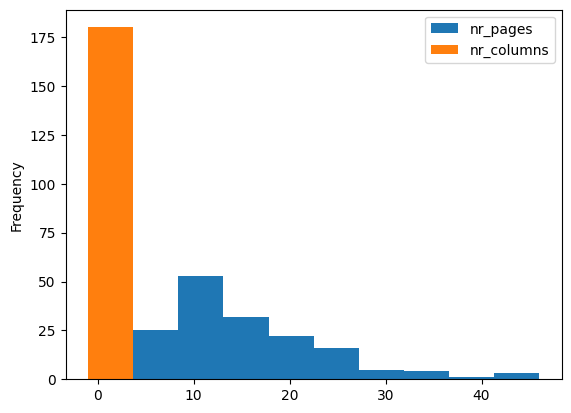

In [176]:
paper_infos[["nr_pages", "nr_columns"]].plot.hist()

<Axes: >

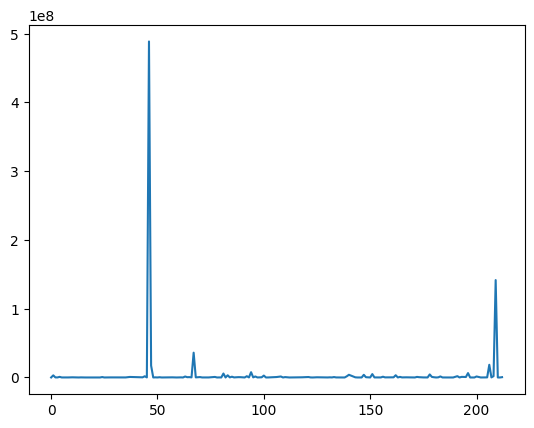

In [167]:
dwca_infos["compressed_size_bytes"].plot()

<Axes: ylabel='Frequency'>

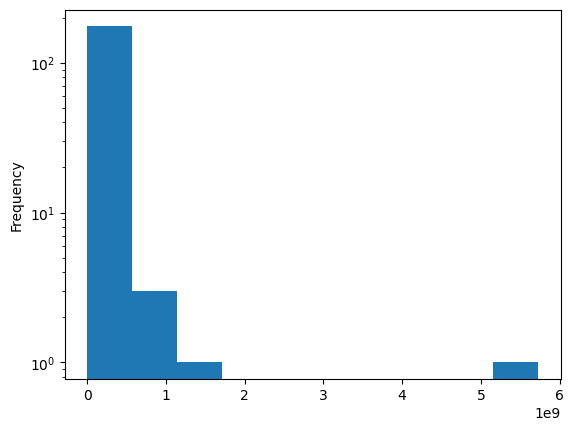

In [175]:
(dwca_infos["raw_size_bytes"]).plot.hist(logy=True)